# Lesson 6 — Multi-step returns, eligibility traces and off-policy estimation

*Chapter I. RL foundations and tabular methods · Section 6 of the lecture notes*

**Foundations:** Silver 4–5; Sutton–Barto Ch. 7, Ch. 12 and §5.5.

> **Learning goal.** Explain credit assignment over several steps; compute an n-step target and an importance ratio; understand the scope of the forward/backward view equivalence.

> **How to read this notebook.** Markdown cells are the lecture, translated to English without changing its content. Boxes that start with **Code** map it to `multistep.py` (n-step return, λ-return, `AccumulatingTrace`, `NStepTDPrediction`, `TDLambdaPrediction`, offline forward/backward updates), `importance_sampling.py` (ratio, ordinary and weighted IS) and the two experiments.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from rlcore import RandomWalk, TabularPolicy, rollout
from multistep import (AccumulatingTrace, TDLambdaPrediction, lambda_return, n_step_return,
                       offline_lambda_return_update, offline_td_lambda_update)
from importance_sampling import OffPolicyMCEvaluator, SupportError, importance_ratio
import experiment_nstep_lambda
import experiment_off_policy_is

## 1. Quick intuition

One-step TD propagates a distant reward over many updates. A multi-step target uses several observed rewards directly before bootstrapping. Eligibility traces store how strongly recently active states/parameters are involved, so that one TD error can also update the past. Importance sampling handles a different problem: the data comes from a policy different from the target. [Silver, Lecture 4]

## 2. The problem being solved

Input: sequences instead of separate transitions. Output: a value or an action-value. The trace formulas below use tabular on-policy prediction; they are not a generic off-policy neural update. When the behavior and the target differ, one must look at whether the specific estimator needs correction, has coverage or has a large variance.

## 3. Core idea and formulas

$$G_t^{(n)} = \sum_{k=0}^{n-1} \gamma^k R_{t+k+1} + \gamma^n V(S_{t+n}). \tag{18}$$

We look ahead $n$ real steps: add up the $n$ observed rewards, then attach the estimate at $S_{t+n}$ for the part not observed. Because that estimate lies $n$ steps from now, its coefficient is $\gamma^n$. $n = 1$ gives the one-step TD target. The formula is written for $t + n < T$; if the terminal is reached earlier, stop the sum at the terminal and drop the bootstrap. $V$ is the version of the estimate used to create the target; it does not replace the terms by itself.

> **Code.** `n_step_return(rewards, states, t, n, gamma, V)` follows Eq. (18), including the early stop at the terminal. On the 19-state random walk (true value of the start state $= 0$) we form $G_0^{(n)}$ on 2000 episodes with a deliberately wrong $V = 0.5$ everywhere. Small $n$ relies on the wrong $V$ (bias), large $n$ relies on many random rewards (variance).

In [2]:
env = RandomWalk(n=19, left_reward=-1.0, seed=0)
policy = TabularPolicy(env.uniform_policy())
V_wrong = np.where(env.terminal, 0.0, 0.5)
episodes = [rollout(env, policy, np.random.default_rng(i)) for i in range(2000)]
print(f"true v(start) = {env.evaluate_policy_exact(env.uniform_policy())[env.start_dist.argmax()]:.1f}")
for n in (1, 2, 4, 8, 16, 32, 1000):
    G = np.array([n_step_return(ep.rewards, ep.states, 0, n, 1.0, V_wrong) for ep in episodes])
    print(f"n = {n:4d}: mean of G_0^(n) = {G.mean():+.3f} (bias {G.mean():+.3f}), variance = {G.var():.3f}")

true v(start) = 0.0
n =    1: mean of G_0^(n) = +0.500 (bias +0.500), variance = 0.000
n =    2: mean of G_0^(n) = +0.500 (bias +0.500), variance = 0.000
n =    4: mean of G_0^(n) = +0.500 (bias +0.500), variance = 0.000
n =    8: mean of G_0^(n) = +0.500 (bias +0.500), variance = 0.000
n =   16: mean of G_0^(n) = +0.485 (bias +0.485), variance = 0.037
n =   32: mean of G_0^(n) = +0.411 (bias +0.411), variance = 0.208
n = 1000: mean of G_0^(n) = +0.016 (bias +0.016), variance = 1.000


$$E_t(s) = \gamma\lambda E_{t-1}(s) + \mathbf 1\{S_t = s\}. \tag{19}$$

You can picture $E_t(s)$ as **the trace of state $s$ having just been visited**. The old trace decays by $\gamma\lambda$; the indicator adds $1$ if the current state is exactly $s$, otherwise adds $0$. Revisiting makes the accumulating trace increase further, so it is not a probability and can be larger than $1$. Initialize $E_{-1}(s) = 0$ at the start of the episode. $\lambda$ controls how long credit is retained, it is not a penalty in the objective.

> **Code.** `AccumulatingTrace.visit(s)` is one application of Eq. (19). The plot follows the traces of the states visited by a short sequence.

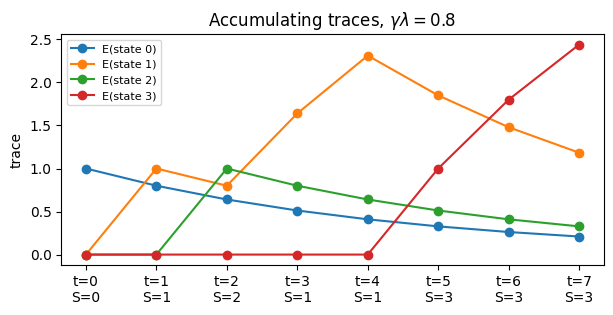

In [3]:
trace = AccumulatingTrace(4, gamma=1.0, lam=0.8)
visits = [0, 1, 2, 1, 1, 3, 3, 3]
history = np.array([trace.visit(s).copy() for s in visits])
fig, ax = plt.subplots(figsize=(7, 3))
for s in range(4):
    ax.plot(history[:, s], marker="o", label=f"E(state {s})")
ax.set_xticks(range(len(visits)), [f"t={t}\nS={s}" for t, s in enumerate(visits)])
ax.set_ylabel("trace"); ax.legend(fontsize=8); ax.set_title(r"Accumulating traces, $\gamma\lambda = 0.8$")
plt.show()

$$V(s) \leftarrow V(s) + \alpha\delta_t E_t(s). \tag{20}$$

The same current TD error is sent to **every state that still has a trace**, but a state with a larger trace gets a larger update. Thanks to this, a new reward can correct the estimates of the states passed recently, instead of only correcting the current state. With $\lambda = 0$, the trace only keeps the current visit, returning to TD(0). This is the tabular on-policy trace update; do not automatically plug this formula into an arbitrary neural/off-policy method.

$\lambda = 0$ only keeps the current state, returning to TD(0). The forward view is a weighted average of the n-step returns; the backward view distributes the TD error through the traces. The classic equivalence needs the appropriate offline/frozen-estimate conditions. Online accumulating TD(λ) should not be considered identical to the forward view at every step; true online TD(λ) resolves this difference. [Sutton–Barto, §§12.1–12.5]

> **Code.** Check the scope of the equivalence on one episode: with $V$ frozen during the episode (offline), the forward view (`offline_lambda_return_update`, λ-returns) and the backward view (`offline_td_lambda_update`, traces) give the same new $V$. Online TD(λ) (`TDLambdaPrediction`, $V$ changes during the episode) gives a slightly different one.

In [4]:
small = RandomWalk(n=7, left_reward=-1.0, seed=1)
ep = rollout(small, TabularPolicy(small.uniform_policy()), np.random.default_rng(1))
V = np.where(small.terminal, 0.0, np.random.default_rng(0).uniform(-0.5, 0.5, small.n_states))
alpha, lam = 0.3, 0.8
forward = offline_lambda_return_update(V, ep, alpha, 1.0, lam)
backward = offline_td_lambda_update(V, ep, alpha, 1.0, lam)
online = TDLambdaPrediction(small.n_states, lam, alpha)
online.V[:] = V                                  # same starting estimate, but it changes during the episode
online.learn_episode(ep)
print("offline forward  :", forward[1:-1].round(4))
print("offline backward :", backward[1:-1].round(4))
print("online TD(lambda):", online.V[1:-1].round(4))
print("max |forward - backward| =", np.max(np.abs(forward - backward)), "| max |forward - online| =",
      round(float(np.max(np.abs(forward - online.V))), 4))

offline forward  : [-0.4611 -0.5751 -0.569  -0.1624 -0.5174  0.0175  0.2295]
offline backward : [-0.4611 -0.5751 -0.569  -0.1624 -0.5174  0.0175  0.2295]
online TD(lambda): [-0.4611 -0.5751 -0.569  -0.2011 -0.3848 -0.136   0.2295]
max |forward - backward| = 2.220446049250313e-16 | max |forward - online| = 0.1534


$$\rho_t = \frac{\pi(A_t \mid S_t)}{\mu(A_t \mid S_t)}. \tag{21}$$

The numerator asks how often the target policy wants to choose this action; the denominator asks how often the behavior chose it. $\rho_t > 1$ makes this sample emphasized when switching the expectation from the behavior to the target; $\rho_t < 1$ makes it less important. For example, probabilities $0.8/0.4$ give a ratio of $2$. The support condition is very important: if the target needs an action to which the behavior gives probability zero, division cannot create the missing information.

Ratios over many steps are multiplied to change the trajectory distribution. The product can be very large or zero; ordinary importance sampling can have a high variance. Weighted importance sampling has a finite-sample bias but can reduce the variance. Do not take a single ratio and plug it into an arbitrary loss.

> **Code.** `importance_ratio` refuses $\mu = 0$ with a `SupportError` instead of returning a meaningless number.

In [5]:
print("rho = 0.8 / 0.4 =", importance_ratio(0.8, 0.4))
print("product over 10 steps of rho = 1.5:", 1.5**10, "| of rho = 0.5:", 0.5**10)

rho = 0.8 / 0.4 = 2.0
product over 10 steps of rho = 1.5: 57.6650390625 | of rho = 0.5: 0.0009765625


## 4. Example and pipeline

Two subsequent rewards $1, 2$, $\gamma = 0.9$, $V(S_{t+2}) = 3$: $G^{(2)}_t = 1 + 0.9\cdot 2 + 0.9^2\cdot 3 = 5.23$. With $\gamma\lambda = 0.8$, a state visited only at the first step has the trace $1, 0.8, 0.64$ over three consecutive steps. If an action has probability $0.8$ under the target and $0.4$ under the behavior, the ratio is $2$.

1. **Data:** Store the sequence segment and the terminal boundary; record the behavior probabilities if the estimator needs them.
2. **Learning:** Create the n-step target or maintain the trace; the off-policy correction must follow the specific algorithm.
3. **Use and evaluation:** Evaluate prediction/control separately; check the data support and the size of the importance weights.

In [6]:
V = np.array([0.0, 0.0, 3.0])                      # V(S_{t+2}) = 3
print("G_t^(2) =", round(n_step_return([1, 2, 0], [0, 1, 2, 2], 0, 2, 0.9, V), 4))
tr = AccumulatingTrace(3, gamma=1.0, lam=0.8)
print("trace of the state visited at the first step:", [round(float(tr.visit(s)[0]), 4) for s in (0, 1, 2)])
print("ratio:", importance_ratio(0.8, 0.4))

G_t^(2) = 5.23
trace of the state visited at the first step: [1.0, 0.8, 0.64]
ratio: 2.0


## 5. Comparison, limits and applications

Multi-step changes bias/variance and the speed of credit propagation; traces do not solve reward misspecification. Off-policy sampling does not create information about actions with zero probability under the behavior. These ideas connect to GAE in Section 8 and offline RL in Section 14.

> **Code.** Experiment 1, the 19-state random walk (Sutton–Barto Example 7.1 / Fig. 12.3 setting): RMS error after 10 episodes as a function of $\alpha$, for several $n$ and $\lambda$. Intermediate $n$ / $\lambda$ give the lowest error on this task, and larger $n$ / $\lambda$ need smaller $\alpha$: the bias/variance trade-off of the multi-step target. All curves use the same episodes.

n_step {'1': (0.8, 0.217), '2': (0.5, 0.165), '4': (0.3, 0.162), '8': (0.2, 0.197), '16': (0.1, 0.218)}
td_lambda {'0.0': (0.8, 0.217), '0.4': (0.6, 0.159), '0.8': (0.2, 0.177), '0.9': (0.2, 0.225)}


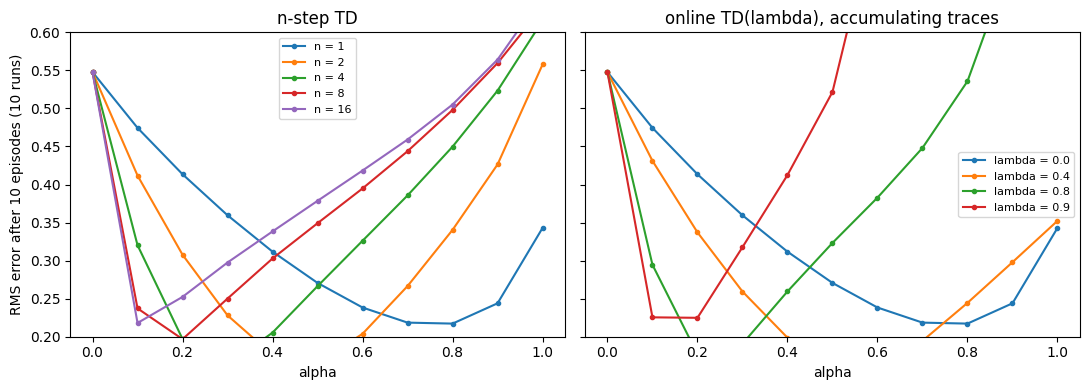

In [7]:
out = experiment_nstep_lambda.run(runs=10, episodes=10)
for family in ("n_step", "td_lambda"):
    print(family, {k: (v["best_alpha"], round(v["best_rms"], 3)) for k, v in out["summary"][family].items()})
plt.show()

> **Code.** Experiment 2, off-policy evaluation on the 5-state random walk: the behavior moves left/right with probability $0.5$, the target moves right with probability $0.75$. Ordinary IS is unbiased but its error shrinks slowly; weighted IS has a much smaller error here. The histogram shows the spread of the trajectory weights $W = \prod_t \rho_t$.

true J(pi) = 0.964; final MSE: ordinary = 0.00757, weighted = 0.00002


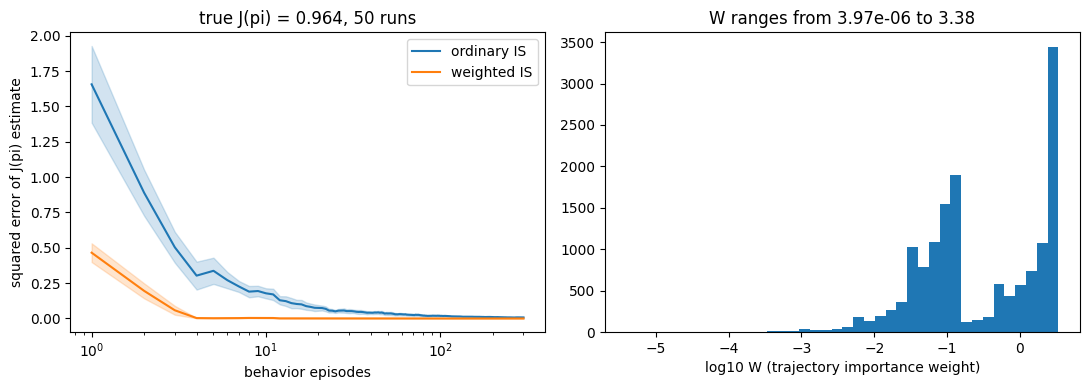

In [8]:
out = experiment_off_policy_is.run(runs=50, episodes=300)
s = out["summary"]
print(f"true J(pi) = {s['true_value']:.3f}; final MSE: ordinary = {s['ordinary IS']['mse_final']:.5f}, "
      f"weighted = {s['weighted IS']['mse_final']:.5f}")
plt.show()

## 6. Exercises

1. If the episode ends right after the two rewards of the example, what is the target?
2. Compute the trace at the next step if the state has just been revisited and the previous trace is $0.64$, $\gamma\lambda = 0.8$.
3. The target needs an action with probability $0.2$, the behavior probability is zero: can importance sampling be used?

In [9]:
print("Exercise 1:", n_step_return([1, 2], [0, 1, 2], 0, 2, 0.9, V))
tr = AccumulatingTrace(1, gamma=1.0, lam=0.8); tr.e[0] = 0.64
print("Exercise 2:", round(float(tr.visit(0)[0]), 4))
try:
    importance_ratio(0.2, 0.0)
except SupportError as err:
    print("Exercise 3:", err)

Exercise 1: 2.8
Exercise 2: 1.512
Exercise 3: behavior probability is 0.0; target probability 0.2 has no support in the data


<details>
<summary><b>Answers (Appendix A)</b></summary>

(1) No bootstrap: $1 + 0.9\cdot 2 = 2.8$. (2) $0.8\cdot 0.64 + 1 = 1.512$. (3) No: the support condition is violated, the ratio is undefined; there are no samples to evaluate that action.
</details>

## 7. Remember and read further

n-step and traces handle credit over time; importance sampling handles a difference of distributions. Do not mix the two roles. Read Sutton–Barto Ch. 7, §§12.1–12.5 and §5.5.